## GLORYS data read and compare
* This notebook is intended to read GLORYS data from Copernicus, and provide comparison plots with HYCOM data.

`version 1.0, July-2026, moeindst`

In [1]:
import numpy as np
import xarray as xr

import os,sys
import copernicusmarine
import cf_xarray
from datetime import datetime

import matplotlib.pyplot as plt
import cmocean

### GLORYS

In [2]:
dataset_id = "cmems_mod_glo_phy_my_0.083deg_P1D-m"
mask_id = "cmems_mod_glo_phy_my_0.083deg_static"
# dataset_id = "SST_MED_SST_L3S_NRT_OBSERVATIONS_010_012_b"

In [3]:
ds_GLORYS = copernicusmarine.open_dataset(dataset_id)
ds_GLORYS_mask = copernicusmarine.open_dataset(mask_id)

INFO - 2026-11-11T14:24:09Z - Selected dataset version: "202311"
INFO - 2026-11-11T14:24:09Z - Selected dataset part: "default"
INFO - 2026-11-11T14:24:13Z - Selected dataset version: "202311"
INFO - 2026-11-11T14:24:13Z - Selected dataset part: "bathy"


In [4]:
### slicing for the desired time period
#-----------------------------------------
period_start = datetime(2015,1,1)
period_end = datetime(2015,3,1)

### slicing for limited region of interest
#-----------------------------------------
ds_GlorMoz15 = ds_GLORYS.sel(
    time=slice(period_start,period_end),
    longitude=slice(39,46.3),
    latitude=slice(-15.7,-6.5),
).drop_vars(['mlotst','bottomT','siconc','sithick','usi','vsi'])

ds_GlorMoz15mask = ds_GLORYS_mask.sel(
    longitude=slice(39,46.3),
    latitude=slice(-15.7,-6.5),
)

### HYCOM

* Since longitude and latitude are not active coordinates in HYCOM, slicing with known lon/lat does not work in a straightforward way. So, I work with array indices.

In [5]:
### Choosing the Reanalysis product
url = "https://tds.hycom.org/thredds/dodsC/GLBa0.08/expt_91.1"
ds = xr.open_dataset(url, decode_times=True)

### Setting the domain extent
x_str=4020
x_end=4160
y_str=1280
y_end=1450

# period_start = datetime(2015,1,1)
# period_end = datetime(2015,3,1)

### Slicing for selected time and region,
### while dropping unnecessary variables.
#-------------------------------------------
ds_HYCOMmoz15 = ds.sel(X=slice(x_str,x_end),
                       Y=slice(y_str,y_end),
                       MT=slice(period_start,period_end),
                      ).drop_vars(
    ['qtot','emp','mld','mlp','surface_temperature_trend','surface_salinity_trend']
                                        )

### Taking care of Longitude format
with xr.set_options(keep_attrs=True):
    ds_HYCOMmoz15 = ds_HYCOMmoz15.assign_coords(
        Longitude=((ds_HYCOMmoz15.Longitude + 180) % 360) - 180
    )

##### Adjusting HYCOM to Mozambique Region
* Due to maximum depth for my domain, HYCOM subset contatin no value for the last two vertical levels (all NaNs). So, here I cut off the last two levels.

In [6]:
ds_HYCOMmoz15 = ds_HYCOMmoz15.isel(Depth=slice(0, -2))

---
### Clustering to speed up procedure
Info on clustering with control on the number of workers and threads:

* 4 workers × 2 threads = 8 Dask threads

    4 workers × 8 GB = 32 GB Dask memory limit


* `free -h` for quick info on machine's memory and `lscpu` for cpu and threads information.

---

In [7]:
### --- interactive ---
# %matplotlib notebook
### --- non-interactive ---
%matplotlib inline

CPU times: user 41.9 s, sys: 16.5 s, total: 58.4 s
Wall time: 28.9 s


Text(0.518, 1.0, '-- 2015-01-15 --')

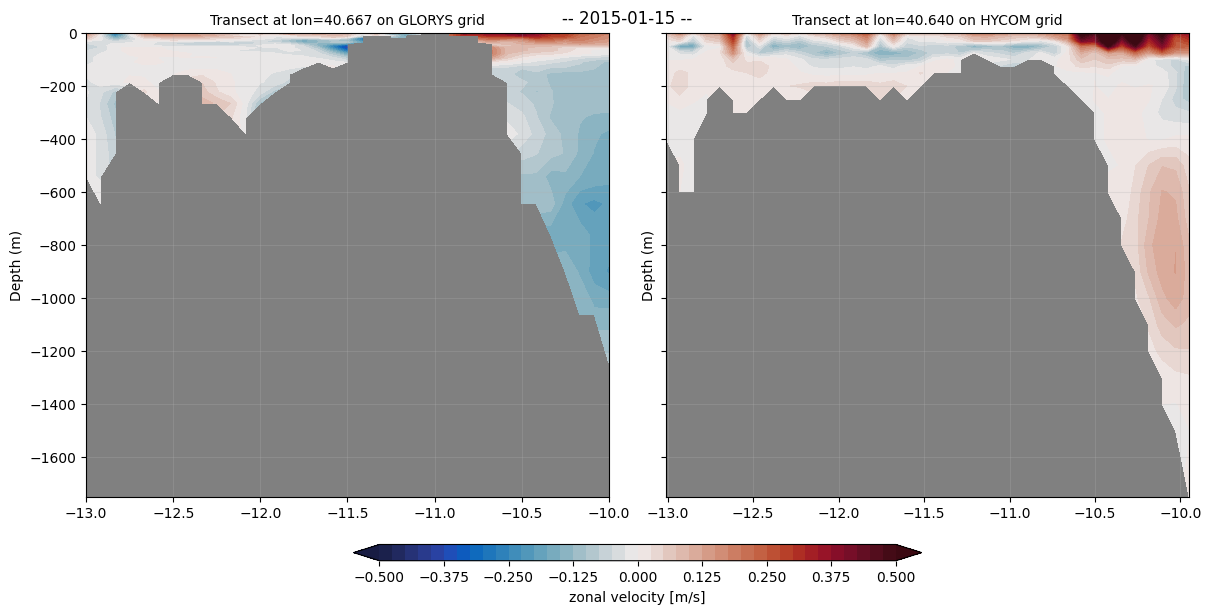

In [8]:
%%time
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(12,6),constrained_layout=True, sharey=True,)

glorys_sect = ds_GlorMoz15.sel(longitude=40.7,method='nearest').sel(latitude=slice(-13.0,-10.0)).sel(depth=slice(0,1750))
hycom_sect = ds_HYCOMmoz15.isel(X=62).isel(Y=slice(61,101)).sel(Depth=slice(0,1750))

# glorys_sect = ds_GlorMoz15.sel(longitude=43.38,method='nearest').sel(latitude=slice(-13.0,-10.0)).sel(depth=slice(0,3750))
# hycom_sect = ds_HYCOMmoz15.isel(X=96).isel(Y=slice(61,101)).sel(Depth=slice(0,3750))

it = '2015-01-15'

###--------------- GLORYS --------------###
v_min, v_max = (-0.5,+0.5)
num_levs= 41

mapp1 = ax1.contourf(
    glorys_sect['latitude'],
    -glorys_sect['depth'],
#     glorys_sect['uo'].isel(time=0),
    glorys_sect['uo'].sel(time=it),
    cmap=cmocean.cm.balance,
    levels=np.linspace(v_min,v_max,num_levs),
#     shading="nearest",
#     vmin=v_min,vmax=v_max,
    extend='both',
                     )
ax1.set_ylabel("Depth (m)")
ax1.set_title(f"Transect at lon={(glorys_sect.longitude.values):.3f} on GLORYS grid", fontsize=10)

###--------------- HYCOM --------------###
mapp2 = ax2.contourf(
    hycom_sect.cf['latitude'],
    -hycom_sect.cf['depth'],
#     hycom_sect.cf['u'].isel(MT=0),
    hycom_sect.cf['u'].sel(MT=it),
    cmap=cmocean.cm.balance,
    levels=np.linspace(v_min,v_max,num_levs),
#     shading="nearest",
#     vmin=v_min,vmax=v_max,
    extend='both',
                     )
ax2.set_ylabel("Depth (m)")
ax2.set_title(f"Transect at lon={(hycom_sect.Longitude[0].values):.3f} on HYCOM grid", fontsize=10)

cbar = plt.colorbar(
    mapp1, ax=[ax1,ax2], label='zonal velocity [m/s]',
    aspect=35, fraction=0.035, orientation='horizontal',
                    )

for ax in (ax1,ax2):
    ax.grid(alpha=0.25)
    ax.set_facecolor("grey")
    
fig.suptitle(f"-- {it} --",fontsize=12, x=0.518, y=1.0)


CPU times: user 47.7 s, sys: 18.3 s, total: 1min 5s
Wall time: 34.2 s


Text(0.518, 1.0, '-- 2015-01-15 --')

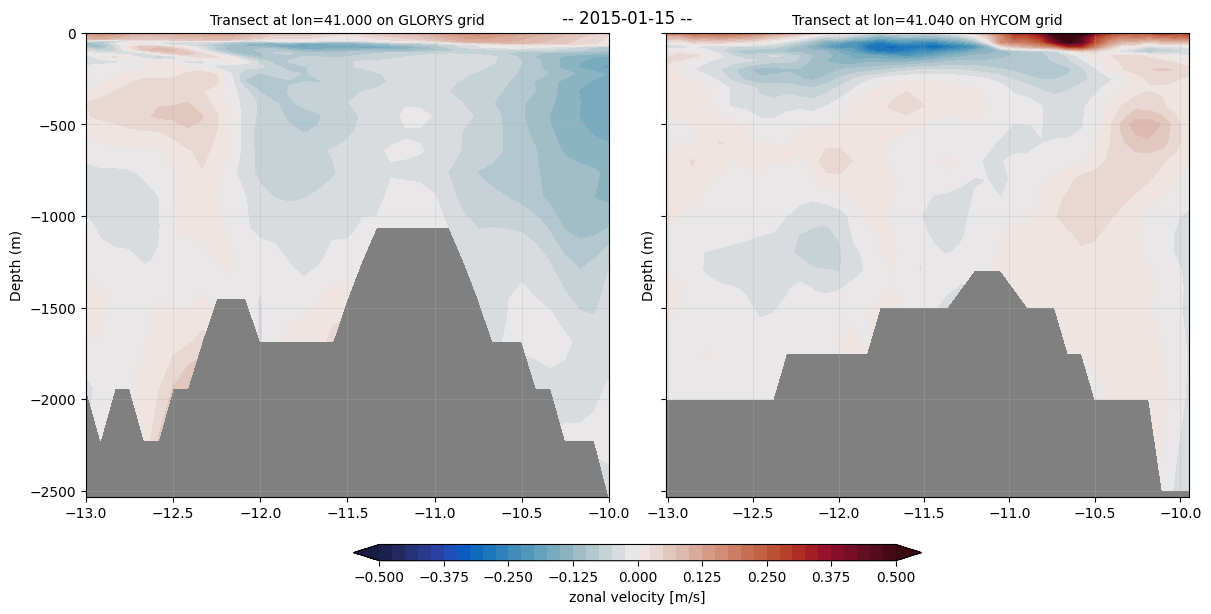

In [9]:
%%time
fig2,(ax1,ax2) = plt.subplots(1,2,figsize=(12,6),constrained_layout=True, sharey=True,)

# glorys_sect = ds_GlorMoz15.sel(longitude=43.36,method='nearest').sel(latitude=slice(-13.0,-10.0)).sel(depth=slice(0,3750))
# hycom_sect = ds_HYCOMmoz15.isel(X=96).isel(Y=slice(61,101)).sel(Depth=slice(0,3750))

glorys_sect = ds_GlorMoz15.sel(longitude=41.04,method='nearest').sel(latitude=slice(-13.0,-10.0)).sel(depth=slice(0,2750))
hycom_sect = ds_HYCOMmoz15.isel(X=67).isel(Y=slice(61,101)).sel(Depth=slice(0,2750))

it = '2015-01-15'

###--------------- GLORYS --------------###
v_min, v_max = (-0.5,+0.5)
num_levs= 41

mapp1 = ax1.contourf(
    glorys_sect['latitude'],
    -glorys_sect['depth'],
#     glorys_sect['uo'].isel(time=0),
    glorys_sect['uo'].sel(time=it),
    cmap=cmocean.cm.balance,
    levels=np.linspace(v_min,v_max,num_levs),
#     shading="nearest",
#     vmin=v_min,vmax=v_max,
    extend='both',
                     )
ax1.set_ylabel("Depth (m)")
ax1.set_title(f"Transect at lon={(glorys_sect.longitude.values):.3f} on GLORYS grid", fontsize=10)

###--------------- HYCOM --------------###
mapp2 = ax2.contourf(
    hycom_sect.cf['latitude'],
    -hycom_sect.cf['depth'],
#     hycom_sect.cf['u'].isel(MT=0),
    hycom_sect.cf['u'].sel(MT=it),
    cmap=cmocean.cm.balance,
    levels=np.linspace(v_min,v_max,num_levs),
#     shading="nearest",
#     vmin=v_min,vmax=v_max,
    extend='both',
                     )
ax2.set_ylabel("Depth (m)")
ax2.set_title(f"Transect at lon={(hycom_sect.Longitude[0].values):.3f} on HYCOM grid", fontsize=10)

cbar = plt.colorbar(
    mapp1, ax=[ax1,ax2], label='zonal velocity [m/s]',
    aspect=35, fraction=0.035, orientation='horizontal',
                    )

for ax in (ax1,ax2):
    ax.grid(alpha=0.25)
    ax.set_facecolor("grey")
    
fig2.suptitle(f"-- {it} --",fontsize=12, x=0.518, y=1.0)


                        <-------------------- End of Document -------------------->